[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_exceed/BA_L4_exceed.ipynb)

# BA_L4_exceed: Tails and Frequency of Peg Breaches

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Empirical exceedance probabilities of the absolute daily deviation from the 1 USD peg (closes and intraday lows) of USDT, USDC and DAI on log-log axes, and the share of days per year with a deviation of at least 15 basis points, 2021 to 23 October 2026. Data: EODHD daily aggregated prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

With the daily deviation $d_t = 10^4\,(P_t - 1)$ in basis points (bp), the empirical exceedance probability is

$$ \hat P(|d| \geq x) = \frac1T \sum_{t=1}^T \mathbb 1\{|d_t| \geq x\} . $$

Left: $\hat P(|d| \geq x)$ on log-log axes for the closes (solid) and for the intraday lows (dashed, $\hat P(d^{low} \leq -x)$).
Right: the share of days in each year with $|d_t| \geq 15$ bp, by coin.

**Data:** EOD Historical Data (EODHD) daily prices of USDT, USDC and DAI, 1 January 2021 to 23 October 2026.

In [5]:
END = '2026-10-23'                      # last day of the lecture sample


def ohlc(sym, start=None, end=END):
    """Daily open, high, low and close from data/market/<sym>.csv."""
    x = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    return x.loc[start:end]


dv, lo = {}, {}
for s in ['USDT', 'USDC', 'DAI']:
    x = ohlc(f'{s}-USD.CC', '2021-01-01')
    dv[s], lo[s] = 1e4 * (x['close'] - 1), 1e4 * (x['low'] - 1)     # deviation of the close and of the intraday low, bp
dv, lo = pd.DataFrame(dv), pd.DataFrame(lo)
print(f'daily closes from {dv.index[0].date()} to {dv.index[-1].date()}: {len(dv)} days')

daily closes from 2021-01-01 to 2026-10-23: 2122 days


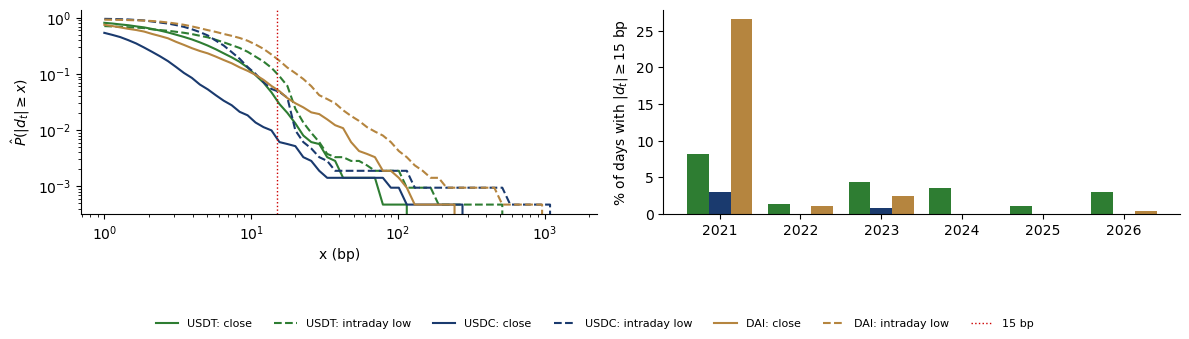

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
xs = np.logspace(0, 3.2, 60)
for s in dv:
    ax[0].loglog(xs, [(dv[s].abs() >= x).mean() for x in xs], color=COL[s], label=f'{s}: close')
    ax[0].loglog(xs, [(lo[s] <= -x).mean() for x in xs], color=COL[s], ls='--', label=f'{s}: intraday low')
ax[0].axvline(15, color=RED, ls=':', lw=1, label='15 bp')
ax[0].set_xlabel('x (bp)'); ax[0].set_ylabel(r'$\hat P(|d_t| \geq x)$')
yrs = dv.abs().ge(15).groupby(dv.index.year).mean() * 100
w = 0.27
for i, s in enumerate(dv):
    ax[1].bar(yrs.index + (i - 1) * w, yrs[s], width=w, color=COL[s])
ax[1].set_ylabel(r'% of days with $|d_t| \geq 15$ bp'); ax[1].set_xticks(yrs.index)
save(fig, 'ba_l4_exceed', 0.17, ncol=7)

## Key numbers: share of days with $|d_t| \geq 15$ bp, by year (%)

In [7]:
yrs.round(1)

,USDT,USDC,DAI
date,,,
2021,8.2,3.0,26.6
2022,1.4,0.0,1.1
2023,4.4,0.8,2.5
2024,3.6,0.0,0.0
2025,1.1,0.0,0.0
2026,3.0,0.0,0.3


**How to read it:** on log-log axes the exceedance curves decay slowly beyond 15 bp, a sign of heavy tails; calling them a power law would need an explicit estimate and test of the tail index.
DAI was beyond 15 bp on about a quarter of the days in 2021 and almost never in 2026; USDT is the only coin that still breaches regularly.